# 20 — One Reusable Metrics Function and a CSV of Regression Results

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

Two recommendations from Hank Butler:

1. *"Standardize Metrics: Refactor metric comparison logic into a reusable function and save results to CSV."*
2. *"Update Error Calculation: Use scikit-learn's standard `root_mean_squared_error` function instead of manually
   calculating RMSE."*

This notebook evaluates the existing **whole-case regression** models with **one small function**, and saves the results
to a CSV file. It is a demonstration of consistent evaluation: **no new models, no tuning and no new features**. Earlier
notebooks are not changed.

The target is the **recorded activity span** in days (first to last recorded event). It is not an administrative delay
or a legal completion time. The three features describe the **whole finished case**, so these models are a regression
exercise and not an early-warning model.

## 2. Load the Data (Same Code as Notebooks 02–05 and 18)

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)

case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data = case_data.reset_index().rename(columns={"case:concept:name": "case_id"})
case_data = case_data[["case_id", "events_per_case", "unique_activities", "unique_resources", "duration_days"]]

print("Completed cases:", len(case_data))

Completed cases: 956


In [3]:
X = case_data[
    [
        "events_per_case",
        "unique_activities",
        "unique_resources"
    ]
]

y = case_data["duration_days"]

The same 764 / 192 split as notebooks 02–05 and 18. The 192 test cases were already used in those notebooks.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

Training cases: 764
Test cases: 192


## 3. Train the Existing Models (Original Settings)

- **Median baseline:** predicts the median training span for every case.
- **Linear Regression** (notebook 02), **Random Forest** (notebook 04), **Gradient Boosting** (notebook 05).
- **VotingRegressor** (notebook 18): the average of the three models, equal weights.

In [5]:
linear_model = LinearRegression().fit(X_train, y_train)
forest_model = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42).fit(X_train, y_train)
boosting_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2,
                                           random_state=42).fit(X_train, y_train)

In [6]:
voting_model = VotingRegressor(estimators=[
    ("linear", LinearRegression()),
    ("forest", RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)),
    ("boosting", GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)),
])
voting_model.fit(X_train, y_train)
voting_pred = voting_model.predict(X_test)

**Predictions** of every approach on the same 192 test cases:

In [7]:
test_predictions = {
    "Median baseline": [y_train.median()] * len(y_test),
    "Linear Regression": linear_model.predict(X_test),
    "Random Forest": forest_model.predict(X_test),
    "Gradient Boosting": boosting_model.predict(X_test),
    "VotingRegressor": voting_pred,
}

## 4. The Reusable Metrics Function

The earlier notebooks calculated the metrics again in every notebook. Some of them originally calculated RMSE by hand
as `mean_squared_error(...) ** 0.5`; those calculations have now been replaced by scikit-learn's standard
`root_mean_squared_error`. Now **one function** does it the same way every time:

- it receives the **actual** values and the **predicted** values;
- it calculates the three metrics with scikit-learn's standard functions, including `root_mean_squared_error` for RMSE;
- it returns them in a dictionary, so every model's results have the same names.

What the three metrics mean:

- **MAE:** the average absolute prediction error in days ("on average, the prediction is this many days wrong").
- **RMSE:** also in days, but large errors get more weight, so a few very wrong predictions raise it a lot.
- **R²:** how much of the variation in the span the model explains, compared with always predicting the mean
  (0 = no better than the mean, 1 = perfect, below 0 = worse than the mean).

In [8]:
def regression_metrics(actual, predicted):
    # the same three metrics for every model
    return {
        "MAE (days)": mean_absolute_error(actual, predicted),
        "RMSE (days)": root_mean_squared_error(actual, predicted),
        "R²": r2_score(actual, predicted),
    }

**Use the function for every model** and collect the results in one table.

In [9]:
rows = []
for name, predicted in test_predictions.items():
    row = regression_metrics(y_test, predicted)
    row["Model"] = name
    rows.append(row)

results = pd.DataFrame(rows)[["Model", "MAE (days)", "RMSE (days)", "R²"]]
results.round(2)

,Model,MAE (days),RMSE (days),R²
0,Median baseline,64.42,153.00,-0.08
1,Linear Regression,59.01,126.02,0.26
2,Random Forest,52.00,109.60,0.44
3,Gradient Boosting,51.19,104.63,0.49
4,VotingRegressor,51.16,110.87,0.43


## 5. Check: the Original Results Are Reproduced

The values must match the outputs of notebooks 02–05 and 18 (rounded to 2 decimals).

In [10]:
recorded = {
    "Median baseline": [64.42, 153.00, -0.08],
    "Linear Regression": [59.01, 126.02, 0.26],
    "Random Forest": [52.00, 109.60, 0.44],
    "Gradient Boosting": [51.19, 104.63, 0.49],
    "VotingRegressor": [51.16, 110.87, 0.43],
}

all_match = True
for name, values in recorded.items():
    now = results.loc[results["Model"] == name, ["MAE (days)", "RMSE (days)", "R²"]].iloc[0].round(2).tolist()
    match = all(abs(a - b) < 0.006 for a, b in zip(now, values))
    all_match = all_match and match
    print(f"{name:<18} recorded {values} | now {now} | matches: {match}")
assert all_match, "The original regression results are not reproduced"

Median baseline    recorded [64.42, 153.0, -0.08] | now [64.42, 153.0, -0.08] | matches: True
Linear Regression  recorded [59.01, 126.02, 0.26] | now [59.01, 126.02, 0.26] | matches: True
Random Forest      recorded [52.0, 109.6, 0.44] | now [52.0, 109.6, 0.44] | matches: True
Gradient Boosting  recorded [51.19, 104.63, 0.49] | now [51.19, 104.63, 0.49] | matches: True
VotingRegressor    recorded [51.16, 110.87, 0.43] | now [51.16, 110.87, 0.43] | matches: True


## 6. Save the Results to a CSV File

A **CSV file** (comma-separated values) is a plain text table that pandas, Excel and many other programs can open, so the
results can be reused without running the notebook again. `index=False` means the DataFrame's row numbers (0, 1, 2, …)
are **not** written as an extra column; the table only contains the four real columns. The values are rounded to
4 decimals, so the file is easy to read.

**Safe to re-run:** if the file already exists, the notebook first reads it. If it contains exactly the same results, it
is left as it is. If it contains anything different, the notebook **stops** instead of replacing it.

In [11]:
results_to_save = results.round(4)

results_folder = project_root / "results"
results_folder.mkdir(exist_ok=True)
csv_file = results_folder / "regression_model_comparison.csv"

In [12]:
def same_results(table_a, table_b):
    # True if both tables have the same columns, model names and values (tiny rounding differences allowed)
    if list(table_a.columns) != list(table_b.columns) or list(table_a["Model"]) != list(table_b["Model"]):
        return False
    numbers_a = table_a.drop(columns="Model").to_numpy()
    numbers_b = table_b.drop(columns="Model").to_numpy()
    return bool((abs(numbers_a - numbers_b) < 1e-9).all())


if csv_file.exists():
    existing = pd.read_csv(csv_file)
    if same_results(existing, results_to_save):
        print("The CSV file already exists with the same results; it was left unchanged.")
    else:
        raise ValueError(f"{csv_file.name} exists but contains different data; it was NOT overwritten.")
else:
    results_to_save.to_csv(csv_file, index=False)
    print("Saved:", csv_file.relative_to(project_root))

Saved: results\regression_model_comparison.csv


**Read the CSV back** and check that it gives the same results:

In [13]:
loaded_results = pd.read_csv(csv_file)

print("Rows and columns in the CSV:", loaded_results.shape)
print("Columns:", list(loaded_results.columns))
print("Same results as calculated:", same_results(loaded_results, results_to_save))
loaded_results

Rows and columns in the CSV: (5, 4)
Columns: ['Model', 'MAE (days)', 'RMSE (days)', 'R²']
Same results as calculated: True


,Model,MAE (days),RMSE (days),R²
0,Median baseline,64.4224,152.9982,-0.0837
1,Linear Regression,59.0098,126.0176,0.2648
2,Random Forest,52.0014,109.5974,0.4439
3,Gradient Boosting,51.1918,104.6257,0.4932
4,VotingRegressor,51.1650,110.8700,0.4309


## 7. Chart: MAE of Every Approach

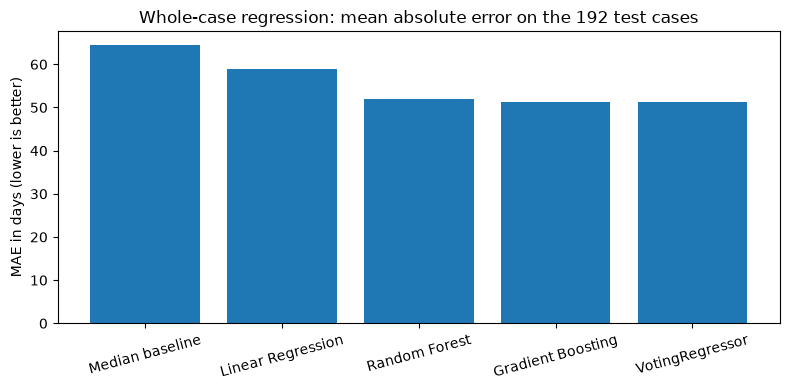

In [14]:
plt.figure(figsize=(8, 4))
plt.bar(loaded_results["Model"], loaded_results["MAE (days)"])
plt.ylabel("MAE in days (lower is better)")
plt.title("Whole-case regression: mean absolute error on the 192 test cases")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 8. Interpretation

- One function, `regression_metrics`, now calculates MAE, RMSE and R² for every model in the same way, with
  scikit-learn's standard functions (`root_mean_squared_error` for RMSE).
- The results are **exactly the same** as in notebooks 02–05 and 18 (for example MAE 51.19 days for Gradient Boosting
  and 51.16 days for VotingRegressor), so the function only makes the evaluation consistent; it does not change any result.
- The table was saved to `results/regression_model_comparison.csv` (5 models, 4 columns) and reading the file back gives
  the same values.
- Gradient Boosting and VotingRegressor have the lowest MAE, about 13 days lower than the median baseline (64.42 days).
  These are still whole-case models, so they cannot be used for early warning.

## 9. Limitations

- This notebook only standardises **how** the metrics are calculated and saved; it does not change any model or result.
- The features describe the **whole finished case**, so these models are **not** early-warning models.
- The target is the **recorded activity span**, not an administrative delay or a legal completion time.
- The 192 test cases were **already used** in notebooks 02–05 and 18, and this is one random split.
- Regression MAE (in days) cannot be compared with the ROC-AUC of the day-30 classification notebooks.
- One Dutch municipality; not SPAR or Montenegro data.